# 01 · EDA dan sanity check

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils import PROC

A = pd.read_parquet(PROC / 'articles.parquet')
daily = pd.read_parquet(PROC / 'daily.parquet').set_index('date')
daily['news_count'] = A.groupby('aligned_trading_date').size().reindex(daily.index).fillna(0)
w = daily[daily.split != 'none']

print(w.groupby('split').agg(n=('ret', 'size'), start=('ret', lambda s: s.index.min().date()), end=('ret', lambda s: s.index.max().date()),
                             hari_ada_berita=('news_count', lambda s: (s > 0).mean().round(2)), berita_per_hari=('news_count', 'mean')))
print('\nTrain: proporsi naik (mayoritas) =', (w[w.split == 'train'].target > 0).mean().round(3))

        n       start         end  hari_ada_berita  berita_per_hari
split                                                              
test   22  2026-07-29  2026-08-31              1.0        43.590909
train  98  2026-01-22  2026-06-29              1.0        48.336735
val    21  2026-06-30  2026-07-28              1.0        41.285714

Train: proporsi naik (mayoritas) = 0.592


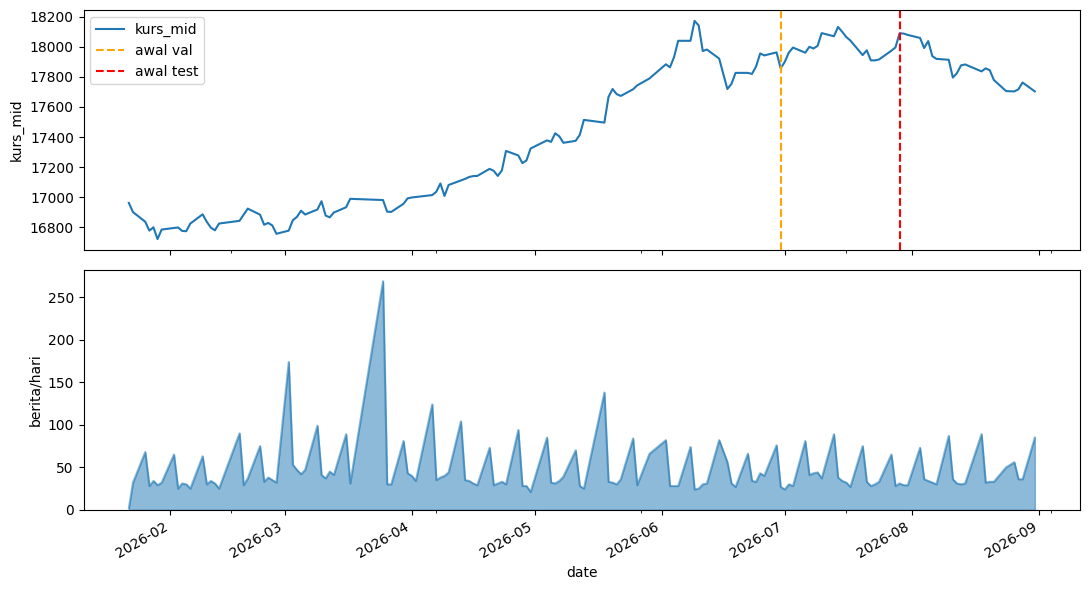

In [2]:
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
w.kurs_mid.plot(ax=ax[0]); ax[0].set_ylabel('kurs_mid')
w.news_count.plot.area(ax=ax[1], alpha=.5); ax[1].set_ylabel('berita/hari')
for s, c in (('val', 'orange'), ('test', 'red')):
    ax[0].axvline(w[w.split == s].index.min(), color=c, ls='--', label=f'awal {s}')
ax[0].legend(); plt.tight_layout()

In [3]:
tr = w[w.split == 'train']
chk = pd.DataFrame({
    'autokorelasi ret lag1 (Train)': [tr.ret.autocorr(1)],
    'corr(news_count_t, |ret_t|)': [tr.news_count.corr(tr.ret.abs())],
    'corr(news_count_t, |ret_t+1|)': [tr.news_count.corr(tr.target.abs())],
}).round(3)
print(chk.T)
assert np.allclose(daily.target.dropna(), daily.ret.shift(-1).dropna()), 'target salah geser'
print('\nartikel per jam terbit (WIB):'); print(A.published_at.dt.hour.value_counts().sort_index().to_string())

                                   0
autokorelasi ret lag1 (Train)  0.078
corr(news_count_t, |ret_t|)   -0.159
corr(news_count_t, |ret_t+1|)  0.210

artikel per jam terbit (WIB):
published_at
0      37
1      20
2      25
3      45
4     108
5     273
6     466
7     563
8     560
9     514
10    584
11    578
12    539
13    576
14    605
15    576
16    589
17    511
18    471
19    508
20    517
21    336
22    155
23     68
